In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os

count=0

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
        count += 1  # 파일을 하나 출력할 때마다 1씩 증가
        
        if count == 20:  
            break  

    if count == 20:
        break
            
# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/organizations/nih-chest-xrays/data/LOG_CHESTXRAY.pdf
/kaggle/input/datasets/organizations/nih-chest-xrays/data/README_CHESTXRAY.pdf
/kaggle/input/datasets/organizations/nih-chest-xrays/data/BBox_List_2017.csv
/kaggle/input/datasets/organizations/nih-chest-xrays/data/test_list.txt
/kaggle/input/datasets/organizations/nih-chest-xrays/data/ARXIV_V5_CHESTXRAY.pdf
/kaggle/input/datasets/organizations/nih-chest-xrays/data/Data_Entry_2017.csv
/kaggle/input/datasets/organizations/nih-chest-xrays/data/train_val_list.txt
/kaggle/input/datasets/organizations/nih-chest-xrays/data/FAQ_CHESTXRAY.pdf
/kaggle/input/datasets/organizations/nih-chest-xrays/data/images_003/images/00006199_010.png
/kaggle/input/datasets/organizations/nih-chest-xrays/data/images_003/images/00004833_016.png
/kaggle/input/datasets/organizations/nih-chest-xrays/data/images_003/images/00006260_000.png
/kaggle/input/datasets/organizations/nih-chest-xrays/data/images_003/images/00004911_010.png
/kaggle/inpu

In [2]:
import torch
from torch import nn
import torchvision.models as models

### 사전학습된 모델 불러오기

In [3]:
device='cuda' if torch.cuda.is_available() else 'cpu'

#best model 불러오기
best_model=models.densenet121(weights='DEFAULT')
best_model.classifier=nn.Linear(1024,14, bias=True)
best_model.to(device)

best_model_state_dict=torch.load('/kaggle/input/notebooks/ryuminhyuk/chexnet/best_chexnet_model.pt', map_location=device)
best_model.load_state_dict(best_model_state_dict)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 250MB/s]


<All keys matched successfully>

In [4]:
print(best_model)

DenseNet(
  (features): Sequential(
    (conv0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (norm0): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu0): ReLU(inplace=True)
    (pool0): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (denseblock1): _DenseBlock(
      (denselayer1): _DenseLayer(
        (norm1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu1): ReLU(inplace=True)
        (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu2): ReLU(inplace=True)
        (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      )
      (denselayer2): _DenseLayer(
        (norm1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu

## Grad-CAM 생성

In [5]:
#순전파/역전파 hook 등록하기
class GradCAM:
    def __init__(self, model, main, sub):
        self.model=model.eval()
        self.register_hook(main, sub)

    def register_hook(self, main, sub):
        #for name, module in self.model.named_children():  #큰 덩어리는 보지 않아서 훅 걸리지 않음
        for name, module in self.model.named_modules():
            #if name==main:
                #for sub_name, sub_module in module[-1].named_children():
                if main in name and sub == name.split('.')[-1]:
                        module.register_forward_hook(self.forward_hook)
                        module.register_full_backward_hook(self.backward_hook)

    def forward_hook(self, module, input, output):
        self.feature_map=output

    def backward_hook(self, module, grad_input, grad_output):
        self.gradient=grad_output[0]    #grad_output은 튜플 형태

    def __call__(self, x):
        output=self.model(x)

        index=output.argmax(axis=1)
        one_hot=torch.zeros_like(output)
        for i in range(output.size(0)):
            one_hot[i][index[i]]=1

        self.model.zero_grad()   #모델의 모든 미분값 0으로
        output.backward(gradient=one_hot, retain_graph=True)    #계산 그래프 보존. 하나의 이미지에서 여러 클래스의 grad_cam을 보고 싶을때 필요.(안그러면 순전파 한번 더해야함)

        a_k=torch.mean(self.gradient, dim=(2,3), keepdim=True)
        grad_cam=torch.sum(a_k*self.feature_map, dim=1)
        grad_cam=torch.relu(grad_cam)

        return grad_cam
        

## Grad-CAM 시각화

In [6]:
from pathlib import Path
class BaseConfig:
    CLASS_NAMES = [
        "Atelectasis",
        "Cardiomegaly",
        "Effusion",
        "Infiltration",
        "Mass",
        "Nodule",
        "Pneumonia",
        "Pneumothorax",
        "Consolidation",
        "Edema",
        "Emphysema",
        "Fibrosis",
        "Pleural_Thickening",
        "Hernia",
    ]
    BASE_PATH = Path("datasets/organizations/nih-chest-xrays/data")

In [7]:
all_xray_df=pd.read_csv('../input/datasets/organizations/nih-chest-xrays/data/Data_Entry_2017.csv')

#image path 만들기
from glob import glob
all_image_paths={os.path.basename(x): x for x in 
                 glob(os.path.join('..','input','datasets','organizations','nih-chest-xrays','data','images_*','images','*.png'))}
print('Scans Found:',len(all_image_paths),'Total Image Index:',all_xray_df.shape[0])
all_xray_df['path']=all_xray_df['Image Index'].map(all_image_paths.get) 

Scans Found: 112120 Total Image Index: 112120


In [8]:
all_xray_df=all_xray_df[['Image Index','Finding Labels','Patient ID','path']]


#원 핫 인코딩 만들기
from tqdm.notebook import tqdm

labels_matrix=np.zeros(shape=(len(all_xray_df),14))
for idx, label in tqdm(enumerate(all_xray_df['Finding Labels'].values), total=len(all_xray_df)):
    labels=label.split('|')
    label_array=np.zeros(len(BaseConfig.CLASS_NAMES))
    for l in labels:
        if l in BaseConfig.CLASS_NAMES:
            label_array[BaseConfig.CLASS_NAMES.index(l)]=1    #원 핫 인코딩으로 바꾸기, No Finding은 전부 0으로
    labels_matrix[idx]=label_array



d={k:v for k,v in zip(BaseConfig.CLASS_NAMES, labels_matrix.transpose())}

for k,v in d.items():
    all_xray_df[k]=v

all_xray_df.head()

  0%|          | 0/112120 [00:00<?, ?it/s]

,Image Index,Finding Labels,Patient ID,path,Atelectasis,Cardiomegaly,Effusion,Infiltration,Mass,Nodule,Pneumonia,Pneumothorax,Consolidation,Edema,Emphysema,Fibrosis,Pleural_Thickening,Hernia
0,00000001_000.png,Cardiomegaly,1,../input/datasets/organizations/nih-chest-xray...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,00000001_001.png,Cardiomegaly|Emphysema,1,../input/datasets/organizations/nih-chest-xray...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,00000001_002.png,Cardiomegaly|Effusion,1,../input/datasets/organizations/nih-chest-xray...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,00000002_000.png,No Finding,2,../input/datasets/organizations/nih-chest-xray...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,00000003_000.png,Hernia,3,../input/datasets/organizations/nih-chest-xray...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [9]:
#14개 클래스별 대표 이미지 추출
represen_img={}

for disease in BaseConfig.CLASS_NAMES:
    img_path = all_xray_df.loc[all_xray_df[disease] == 1, 'path'].iloc[0]
    represen_img[disease] = img_path

In [10]:
from PIL import Image
from torch.nn import functional as F
import albumentations as A
from albumentations.pytorch import ToTensorV2
import matplotlib.pyplot as plt

transform=A.Compose([
    A.Resize(224,224),
    A.Normalize(),
    ToTensorV2()
])

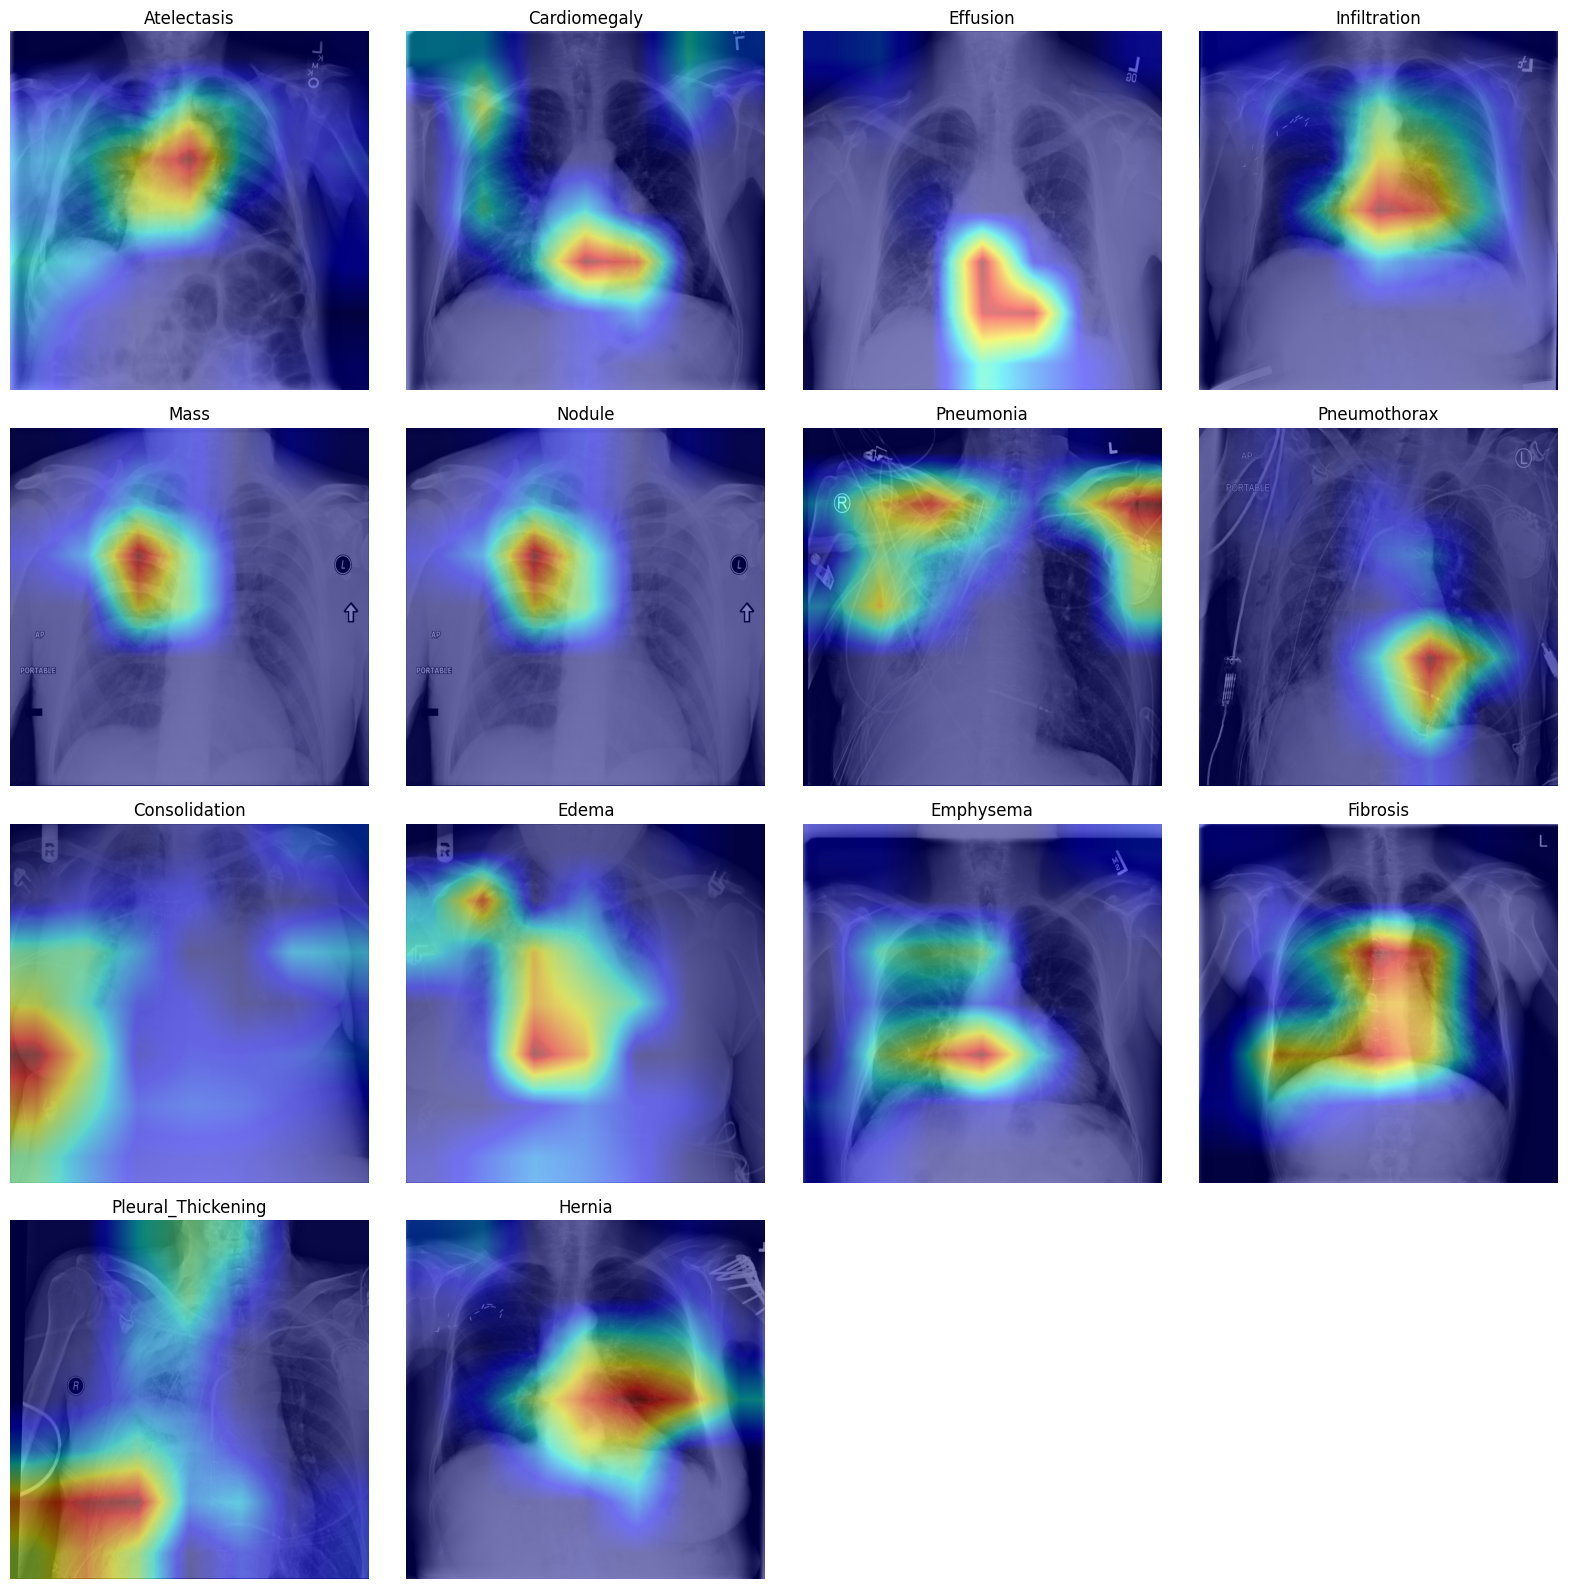

In [11]:
#시각화
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 4, figsize=(16, 16))

axes = axes.ravel()   #1차원으로


for idx, (disease, img_path) in enumerate(represen_img.items()):
    image=Image.open(img_path).convert("RGB")

    transformed_img=transform(image=np.array(image))
    tf_image=transformed_img['image']

    model=GradCAM(model=best_model, main='denselayer16', sub='conv2')
    grad_cam=model(tf_image.unsqueeze(0))

    grad_cam=F.interpolate(
        input=grad_cam.unsqueeze(0),
        size=(image.size[0], image.size[1]),    #iamge는 PIL이라 ()가 아닌 []로 접근
        mode='bilinear'
    ).squeeze().detach().numpy()

    axes[idx].imshow(image)
    axes[idx].imshow(grad_cam, cmap='jet', alpha=0.5)
    axes[idx].set_title(disease, fontsize=12)
    axes[idx].axis('off')

for empty_idx in range(len(represen_img), len(axes)):
    axes[empty_idx].axis('off')

plt.tight_layout()
plt.show()